# Phase 2, Model 2: Continued pretraining (CPT) of GPT-2 small, starting from the official `base_project`



## 0. Settings

In [ ]:
BASE_DIR =  "/content/drive/MyDrive/base_project/checkpoints/gpt2-small/base_project"   # the Drive shortcut to the official Notebook 1 checkpoint
OUT_NAME = "cpt_from_base_project_2"                 # NEW checkpoint folder for this run (never overwritten)
RUN_SMOKE = False                                  # True = first a 5% trial run (checkpoints on the Colab disk only)
REPO_URL = "https://github.com/Nutrition-Assistant-System/Nutrition-Assistant"
REPO_DIR = "/content/Nutrition-Assistant"

## 1. Setup (Google Drive, team repo, GPU)

In [ ]:
import os, subprocess, sys
from google.colab import drive
drive.mount("/content/drive")

os.chdir("/content")                                                      # leave the repo folder before deleting it
subprocess.run(["rm", "-rf", REPO_DIR], check=True)                       # local Colab copy only (not Drive)
r = subprocess.run(["git", "clone", "-q", REPO_URL, REPO_DIR], capture_output=True, text=True)
if r.returncode != 0:
    raise SystemExit(f"git clone failed:\n{r.stderr}\nCheck the internet connection and that the repository is public.")
os.chdir(REPO_DIR)
subprocess.run(["cp", "Notebooks/config.yaml", "config.yaml"], check=True)
os.makedirs("src", exist_ok=True); open("src/__init__.py", "a").close()
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "accelerate", "matplotlib", "pyyaml"], check=True)

import torch
if not torch.cuda.is_available():
    raise SystemExit("No GPU: Runtime -> Change runtime type -> T4 GPU -> Save, then Runtime -> Run all.")
print("GPU:", torch.cuda.get_device_name(0), "| repo:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4 | repo: /content/Nutrition-Assistant


## 2. Check the shared `base_project`

In [ ]:
import json, hashlib
REQUIRED = ["config.json", "model.safetensors", "tokenizer.json", "tokenizer_config.json", "project_tokens.json"]
if not os.path.isdir(BASE_DIR):
    raise SystemExit(f"NOT FOUND: {BASE_DIR}\nMy Drive contains: {sorted(os.listdir('/content/drive/MyDrive'))}\n"
                     "Add the shortcut (Shared with me -> base_project -> Organize -> Add shortcut -> My Drive), then run "
                     "drive.mount('/content/drive', force_remount=True) and Run all again. If the shortcut is in a subfolder, "
                     "set BASE_DIR in section 0.")
for f in sorted(os.listdir(BASE_DIR)):
    print(f"  {f:28s} {os.path.getsize(os.path.join(BASE_DIR, f)) / 1e6:9.1f} MB")
missing = [f for f in REQUIRED if f not in os.listdir(BASE_DIR)]
if missing:
    raise SystemExit(f"base_project is incomplete: missing {missing}. Ask the owner to check the shared folder.")

def file_sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 22), b""):
            h.update(chunk)
    return h.hexdigest()
BASE_SHA = file_sha256(f"{BASE_DIR}/model.safetensors")             # reads the whole file: proves it is readable
print("required files present: PASS")
print("model.safetensors sha256:", BASE_SHA)

from transformers import AutoTokenizer
_t = AutoTokenizer.from_pretrained(BASE_DIR)
ids = [_t.convert_tokens_to_ids(t) for t in ["<|user|>", "<|assistant|>", "<|end|>"]]
if len(_t) != 50260 or ids != [50257, 50258, 50259]:
    raise SystemExit(f"base_project tokenizer is not the project tokenizer (size {len(_t)}, ids {ids}).")
print("tokenizer: 50,260 tokens, ids 50257-50259: PASS")

  config.json                        0.0 MB
  generation_config.json             0.0 MB
  model.safetensors                497.8 MB
  project_tokens.json                0.0 MB
  tokenizer.json                     3.6 MB
  tokenizer_config.json              0.0 MB
required files present: PASS
model.safetensors sha256: 9858160fdf49909f2c5cd57ac805bb1a77752f5892dc99a9cff86ce65e8717bb
tokenizer: 50,260 tokens, ids 50257-50259: PASS


## 3. Write the code files
All helper code goes into one file, `src/project_model.py`; the shared prompt/generation and scoring code are the same files Notebook 1 used.

In [ ]:
%%writefile src/project_model.py
"""Shared helpers for Phase 2 (config v2): config + paths, the PROJECT tokenizer/model, CPT data blocks,
perplexity, trainer pieces. Everything that must be identical across Base / CPT / SFT lives here.
"""
import os, sys, json, math, time, random, shutil, hashlib, inspect, getpass, urllib.request
import numpy as np
import torch
import torch.nn.functional as F
import yaml

ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))


def load_config(path=None):
    path = path or os.environ.get("NUTRI_CONFIG") or os.path.join(ROOT, "config.yaml")
    with open(path) as f:
        return yaml.safe_load(f)


def resolve_root(cfg):
    """Drive on Colab, the fallback folder if Drive is not mounted, the repo folder when run elsewhere.
    NUTRI_ROOT overrides everything."""
    if os.environ.get("NUTRI_ROOT"):
        return os.environ["NUTRI_ROOT"]
    p = cfg["paths"]
    if os.path.isdir("/content/drive/MyDrive"):
        return p["drive_root"]
    if os.path.isdir("/content"):
        print("WARNING: Google Drive is not mounted; files go to", p["local_fallback_root"], "and are LOST at session end.")
        return p["local_fallback_root"]
    return ROOT


def get_secret(cfg, name):
    var = cfg["credentials"]["secrets"][name]
    for src in cfg["credentials"]["source_order"]:
        if src == "colab_secrets":
            try:
                from google.colab import userdata
                v = userdata.get(var)
                if v:
                    return v
            except Exception:
                pass
        elif src == "environment" and os.environ.get(var):
            return os.environ[var]
        elif src == "prompt":
            return getpass.getpass(f"{var}: ")
    return None


def read_text(cfg, rel_path, local_fallback=None):
    """Read a data file from the project GitHub repo (raw URL). Falls back to a local copy if the download fails."""
    ds = cfg["data_sources"]
    url = ds["base_url"].rstrip("/") + "/" + rel_path
    headers = {}
    if ds.get("private_repo"):
        tok = get_secret(cfg, "github")
        if tok:
            headers["Authorization"] = f"token {tok}"
    try:
        req = urllib.request.Request(url, headers=headers)
        with urllib.request.urlopen(req, timeout=60) as r:
            return r.read().decode("utf-8"), url
    except Exception as e:
        if local_fallback and os.path.exists(local_fallback):
            print(f"WARNING: could not download {url} ({e}); using local copy {local_fallback}")
            return open(local_fallback, encoding="utf-8").read(), local_fallback
        raise


def sha256_text(t):
    return hashlib.sha256(t.encode("utf-8")).hexdigest()


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def device():
    return "cuda" if torch.cuda.is_available() else "cpu"


def verify_project(cfg, tok, model=None):
    """Every checkpoint must carry the same tokenizer: 3 added special tokens at fixed ids, pad = EOS."""
    pt = cfg["prompting"]["project_tokenizer"]
    assert len(tok) == pt["vocab_size"], f"tokenizer has {len(tok)} tokens, expected {pt['vocab_size']}"
    for t, i in pt["special_token_ids"].items():
        assert tok.convert_tokens_to_ids(t) == i, f"{t} should have id {i}"
    assert tok.pad_token == pt["pad_token"], f"pad token is {tok.pad_token}, expected {pt['pad_token']}"
    if model is not None:
        assert model.get_input_embeddings().num_embeddings == pt["vocab_size"], "embedding size != vocab_size"


def set_stop_ids(cfg, model, tok):
    ids = [tok.convert_tokens_to_ids(t) for t in cfg["prompting"]["stop_token_ids_from"]]
    model.generation_config.eos_token_id = ids
    model.generation_config.pad_token_id = tok.pad_token_id
    model.config.pad_token_id = tok.pad_token_id


def save_project(cfg, model, tok, path):
    set_stop_ids(cfg, model, tok)
    os.makedirs(path, exist_ok=True)
    model.save_pretrained(path)
    tok.save_pretrained(path)
    pt = cfg["prompting"]["project_tokenizer"]
    with open(os.path.join(path, pt["saved_with_every_checkpoint"]), "w") as f:
        json.dump({"vocab_size": pt["vocab_size"], "special_token_ids": pt["special_token_ids"],
                   "pad_token": pt["pad_token"], "config_version": cfg["project"]["config_version"]}, f, indent=2)


def load_project(cfg, path):
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(path)
    model = AutoModelForCausalLM.from_pretrained(path)
    verify_project(cfg, tok, model)
    set_stop_ids(cfg, model, tok)
    return tok, model.to(device())


def build_project_base(cfg, model_key):
    """Original pretrained model + the 3 project special tokens."""
    from transformers import AutoTokenizer, AutoModelForCausalLM
    m, pt, st = cfg["models"][model_key], cfg["prompting"]["project_tokenizer"], cfg["prompting"]["special_tokens"]
    tok = AutoTokenizer.from_pretrained(m["model_id"], revision=m["revision"])
    if len(tok) != pt["base_vocab_size"]:
        raise SystemExit(f"{model_key}: tokenizer has {len(tok)} tokens but config expects base_vocab_size "
                         f"{pt['base_vocab_size']}. The project tokenizer block is written for GPT-2 small only.")
    tok.add_special_tokens({"additional_special_tokens": [st["user"], st["assistant"], st["end"]]})
    tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(m["model_id"], revision=m["revision"])
    model.resize_token_embeddings(len(tok))            # new rows: mean of existing rows (transformers default)
    verify_project(cfg, tok, model)
    if pt.get("tied_lm_head") and hasattr(model, "lm_head"):
        assert model.lm_head.weight.data_ptr() == model.get_input_embeddings().weight.data_ptr(), "lm_head lost its tie"
    set_stop_ids(cfg, model, tok)
    return tok, model.to(device())


def to_blocks(tok, text, block_size, eos_id, cfg, fraction=1.0):
    """Documents are separated by blank lines. Join them with EOS and cut into fixed blocks (remainder dropped)."""
    for s in cfg["prompting"]["special_tokens"].values():
        assert s not in text, f"corpus contains the reserved token {s}"
    docs = [d for d in text.split("\n\n") if d.strip()]
    if fraction < 1.0:
        docs = docs[:max(1, int(len(docs) * fraction))]
    ids = []
    for d in docs:
        ids.extend(tok(d, add_special_tokens=False)["input_ids"])
        ids.append(eos_id)
    n = len(ids) // block_size
    blocks = [ids[i * block_size:(i + 1) * block_size] for i in range(n)]
    stats = {"documents": len(docs), "tokens": len(ids), "blocks": n, "tokens_used": n * block_size,
             "tokens_dropped_at_end": len(ids) - n * block_size}
    return blocks, stats


class BlockDataset(torch.utils.data.Dataset):
    def __init__(self, blocks):
        self.blocks = blocks
    def __len__(self):
        return len(self.blocks)
    def __getitem__(self, i):
        x = torch.tensor(self.blocks[i], dtype=torch.long)
        return {"input_ids": x, "labels": x.clone()}      # labels are ALL tokens, including EOS


def cpt_collate(batch):
    """No padding (all blocks have the same length) and no label masking, so EOS labels are kept.
    DataCollatorForLanguageModeling would mask EOS because pad == EOS."""
    return {"input_ids": torch.stack([b["input_ids"] for b in batch]),
            "labels": torch.stack([b["labels"] for b in batch])}


@torch.no_grad()
def heldout_perplexity(model, blocks, base_vocab, batch_size=8):
    """exp(mean next-token loss) over the held-out blocks, softmax over the first base_vocab logits only, dropout off."""
    was_training = model.training
    model.eval()
    dev = next(model.parameters()).device
    total, count = 0.0, 0
    for i in range(0, len(blocks), batch_size):
        x = torch.tensor(blocks[i:i + batch_size], dtype=torch.long, device=dev)
        logits = model(input_ids=x).logits[..., :base_vocab].float()
        total += F.cross_entropy(logits[:, :-1].reshape(-1, base_vocab), x[:, 1:].reshape(-1), reduction="sum").item()
        count += x[:, 1:].numel()
    model.train(was_training)
    return math.exp(total / count), total / count


@torch.no_grad()
def complete_prompts(cfg, tok, model, prompts):
    g = cfg["generation"]
    model.eval()
    out = []
    for p in prompts:
        enc = tok(p, return_tensors="pt", add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=g["max_new_tokens"], do_sample=g["do_sample"],
                             repetition_penalty=g["repetition_penalty"], pad_token_id=tok.pad_token_id)
        out.append(tok.decode(gen[0][enc["input_ids"].shape[1]:], skip_special_tokens=True).strip())
    return out


def make_trainer_class(base_vocab):
    from transformers import Trainer

    class CPTTrainer(Trainer):
        """Loss over the first base_vocab logits, so eval_loss == ln(held-out perplexity) exactly."""
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            out = model(input_ids=inputs["input_ids"])
            logits = out.logits[..., :base_vocab].float()
            labels = inputs["labels"]
            loss = F.cross_entropy(logits[:, :-1].reshape(-1, base_vocab), labels[:, 1:].reshape(-1))
            return (loss, out) if return_outputs else loss
    return CPTTrainer


def training_args(**kw):
    """TrainingArguments across transformers 4.x and 5.x (renamed / removed arguments)."""
    from transformers import TrainingArguments
    accepted = set(inspect.signature(TrainingArguments.__init__).parameters)
    if "eval_strategy" not in accepted and "evaluation_strategy" in accepted:
        kw["evaluation_strategy"] = kw.pop("eval_strategy")
    if "warmup_ratio" in kw and "warmup_ratio" not in accepted:
        kw["warmup_steps"] = float(kw.pop("warmup_ratio"))
    dropped = [k for k in kw if k not in accepted]
    for k in dropped:
        kw.pop(k)
    if dropped:
        print(f"(TrainingArguments: ignoring unsupported settings {dropped})")
    return TrainingArguments(**kw)


def plot_losses(log_history, evals, path, title):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    tr = [(h["epoch"], h["loss"]) for h in log_history if "loss" in h and "eval_loss" not in h]
    plt.figure(figsize=(6, 4))
    if tr:
        plt.plot(*zip(*tr), label="training loss")
    if evals:
        plt.plot([e["epoch"] for e in evals], [e["eval_loss"] for e in evals], "o-", label="validation loss (held-out)")
    plt.xlabel("epoch"); plt.ylabel("cross-entropy loss"); plt.title(title); plt.legend(); plt.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.close()

Writing src/project_model.py


In [ ]:
%%writefile src/prompting_tokens.py
"""Prompting and special-token helpers shared by all three Phase 2 notebooks (Base, CPT, SFT).

Each notebook pastes this cell unchanged, so prompt formatting, tokenization, loss masking, stopping
and perplexity are identical in every stage. Decided in the token review:
  * Approach B: <|user|>, <|assistant|>, <|end|> are added as special tokens ONCE (Base notebook, via
    prepare_project_tokenizer). Every later stage loads with load_project_checkpoint, which checks the
    tokenizer and never adds tokens. Same prompt -> same token IDs in Base, CPT, SFT and scoring.
  * Perplexity is computed over the ORIGINAL vocabulary only (first base_vocab_size logits), so adding
    the 3 tokens cannot change it and Base / CPT / SFT perplexities are directly comparable.
"""
import json, math, os
import torch


def build_prompt(question, cfg):
    """The ONE prompt format used for Base, CPT and SFT, in training and in evaluation."""
    return cfg["prompting"]["template"].format(question=question.strip())


def build_target(answer, cfg):
    """SFT target: a leading space, the answer, then the end marker directly (no space before it,
    which would add an extra "Ġ" token the model must learn to emit before stopping)."""
    return cfg["prompting"]["target"].format(answer=answer.strip())


def _markers(cfg):
    st = cfg["prompting"]["special_tokens"]
    return [st["user"], st["assistant"], st["end"]]


def stop_token_ids(tok, cfg):
    """Generation stops at <|end|> (learned in SFT) or at the tokenizer's EOS (<|endoftext|>)."""
    return sorted({tok.convert_tokens_to_ids(cfg["prompting"]["special_tokens"]["end"]), tok.eos_token_id})


def prepare_project_tokenizer(tok, model, cfg):
    """Base notebook ONLY: add the 3 special tokens, set padding, resize the embeddings, record the IDs."""
    if any(t in tok.get_vocab() for t in _markers(cfg)):
        raise RuntimeError("special tokens already present: load later stages with load_project_checkpoint")
    tok.add_special_tokens({"additional_special_tokens": _markers(cfg)})
    if tok.pad_token is None:                      # GPT-2 has no pad token: pad with EOS (always masked)
        tok.pad_token = tok.eos_token
    model.resize_token_embeddings(len(tok))        # new rows sampled around the mean of existing rows
    return _finish(tok, model, cfg)


def _finish(tok, model, cfg):
    model.generation_config.eos_token_id = stop_token_ids(tok, cfg)
    model.generation_config.pad_token_id = tok.pad_token_id
    return {"special_token_ids": {t: tok.convert_tokens_to_ids(t) for t in _markers(cfg)},
            "vocab_size": len(tok), "base_vocab_size": cfg["prompting"]["project_tokenizer"]["base_vocab_size"],
            "eos_token_id": tok.eos_token_id, "pad_token_id": tok.pad_token_id,
            "stop_token_ids": stop_token_ids(tok, cfg)}


def check_project_tokenizer(tok, model, cfg):
    """Fail loudly if a tokenizer/model pair is not the project tokenizer from config.yaml."""
    exp = cfg["prompting"]["project_tokenizer"]
    problems = []
    for t, i in exp["special_token_ids"].items():
        enc = tok.encode(t, add_special_tokens=False)
        if enc != [i]:
            problems.append(f"{t} encodes to {enc}, expected [{i}]")
    if len(tok) != exp["vocab_size"]:
        problems.append(f"tokenizer size {len(tok)}, expected {exp['vocab_size']}")
    if model.get_input_embeddings().weight.shape[0] != len(tok):
        problems.append(f"embedding rows {model.get_input_embeddings().weight.shape[0]} != tokenizer size {len(tok)}")
    if tok.pad_token_id is None:
        problems.append("no pad token")
    if exp.get("tied_lm_head") and model.lm_head.weight.data_ptr() != model.get_input_embeddings().weight.data_ptr():
        problems.append("input and output embeddings are no longer tied")
    if problems:
        raise RuntimeError("Project tokenizer check failed:\n  - " + "\n  - ".join(problems))
    return True


def load_project_checkpoint(path, cfg, device=None):
    """CPT, SFT and scoring: load a saved checkpoint and its tokenizer; check; never add tokens."""
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(path)
    model = AutoModelForCausalLM.from_pretrained(path)
    check_project_tokenizer(tok, model, cfg)
    _finish(tok, model, cfg)
    if device:
        model.to(device)
    return tok, model.eval()


def cpt_collate(blocks):
    """CPT batches: every block is exactly block_size tokens, so there is no padding and every token,
    including the <|endoftext|> between documents, is a training label. (DataCollatorForLanguageModeling
    must NOT be used: with pad = EOS it would turn every document-boundary EOS label into -100.)"""
    ids = torch.tensor([b["input_ids"] for b in blocks])
    return {"input_ids": ids, "attention_mask": torch.ones_like(ids), "labels": ids.clone()}


def sft_collate(batch, pad_id):
    """SFT batches: right-pad input_ids with pad_id (attention 0) and labels with -100 (no loss)."""
    m = max(len(x["input_ids"]) for x in batch)
    pad = lambda x, v: x + [v] * (m - len(x))
    return {"input_ids": torch.tensor([pad(x["input_ids"], pad_id) for x in batch]),
            "attention_mask": torch.tensor([pad([1] * len(x["input_ids"]), 0) for x in batch]),
            "labels": torch.tensor([pad(x["labels"], -100) for x in batch])}


def encode_sft_example(tok, question, answer, cfg, max_length):
    """Prompt and target are tokenized separately (as at inference, where only the prompt is given),
    then joined. Labels are -100 on prompt tokens: the loss is on the answer and <|end|> only."""
    p_ids = tok(build_prompt(question, cfg), add_special_tokens=False)["input_ids"]
    a_ids = tok(build_target(answer, cfg), add_special_tokens=False)["input_ids"]
    if len(p_ids) + len(a_ids) > max_length:
        raise ValueError(f"example longer than max_length={max_length}: the <|end|> marker would be cut off")
    return {"input_ids": p_ids + a_ids, "labels": [-100] * len(p_ids) + a_ids}


@torch.no_grad()
def heldout_perplexity(tok, model, text, cfg, block_size=512):
    """Held-out perplexity over the ORIGINAL vocabulary: logits are cut to the first base_vocab_size
    entries before the softmax. The held-out text never contains the 3 new tokens, so this equals the
    perplexity of the unmodified model and is comparable across Base, CPT and SFT."""
    V = cfg["prompting"]["project_tokenizer"]["base_vocab_size"]
    ids = tok(text, add_special_tokens=False)["input_ids"]
    if any(i >= V for i in ids):
        raise ValueError("held-out text contains project special tokens")
    ids = torch.tensor(ids)
    was_training = model.training
    model.eval()                                   # dropout off: perplexity must be deterministic
    nll, count = 0.0, 0
    for i in range(0, len(ids) - 1, block_size):
        chunk = ids[i:i + block_size].unsqueeze(0).to(model.device)
        if chunk.shape[1] < 2:
            continue
        logits = model(chunk).logits[0, :-1, :V].float()
        nll += torch.nn.functional.cross_entropy(logits, chunk[0, 1:], reduction="sum").item()
        count += chunk.shape[1] - 1
    model.train(was_training)
    return math.exp(nll / count)


def clean_answer(text, cfg):
    """Cut a decoded answer at the first stop string (end marker, a new turn, or EOS text)."""
    for s in cfg["prompting"]["stop_strings"]:
        i = text.find(s)
        if i != -1:
            text = text[:i]
    return text.strip()


@torch.no_grad()
def generate_answer(tok, model, question, cfg):
    """The ONE function every stage and score.py uses to query a model (greedy, same length)."""
    g = cfg["generation"]
    stops = stop_token_ids(tok, cfg)
    enc = tok(build_prompt(question, cfg), return_tensors="pt", add_special_tokens=False).to(model.device)
    out = model.generate(**enc, max_new_tokens=g["max_new_tokens"], do_sample=False, num_beams=1,
                         repetition_penalty=g.get("repetition_penalty", 1.0),
                         eos_token_id=stops, pad_token_id=tok.pad_token_id)
    new = out[0][enc["input_ids"].shape[1]:]
    stopped = bool(len(new)) and int(new[-1]) in stops
    text = tok.decode(new, skip_special_tokens=False)
    return clean_answer(text, cfg), {"new_tokens": int(len(new)), "stopped_at_stop_token": stopped}


def save_with_tokenizer(model, tok, out_dir, cfg):
    """Save model + tokenizer + recorded token IDs together. Use for EVERY saved checkpoint (each CPT
    pass, best CPT, best SFT) so any folder can be loaded with load_project_checkpoint."""
    os.makedirs(out_dir, exist_ok=True)
    model.save_pretrained(out_dir)
    tok.save_pretrained(out_dir)
    json.dump(_finish(tok, model, cfg), open(os.path.join(out_dir, "project_tokens.json"), "w"), indent=2)

Writing src/prompting_tokens.py


In [ ]:
%%writefile src/scoring.py
"""Scoring rules shared by all three Phase 2 notebooks and by score.py (approved points B and C).

Every model is scored by the SAME functions:
  * key_match (18): 1 if a key value from `key_answer` appears in the answer after normalising
                    (lowercase, collapse spaces, remove thousands separators); declining scores 0.
  * decline   (4):  1 if the answer declines (patterns in config.yaml), else 0.
  * manual    (8):  graded by two team members; PENDING until both have graded (never counted as 0).
"""
import hashlib, json, re
import pandas as pd


def test_fingerprint(df):
    """sha256 of the compact JSON list of [id, question, expected_answer] (config.yaml: test_set.fingerprint)."""
    rows = [[str(r.id), str(r.question), str(r.expected_answer)] for r in df.itertuples()]
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(",", ":")).encode("utf-8")).hexdigest()


def normalise(text):
    t = str(text).lower()
    t = re.sub(r"(?<=\d),(?=\d{3}(?!\d))", "", t)     # thousands separator: 1,139 -> 1139
    return re.sub(r"\s+", " ", t).strip()


def numbers(text):
    return set(re.findall(r"\d+(?:\.\d+)?", normalise(text)))


def declined(answer, cfg):
    pats = cfg["evaluation"]["should_decline"]["patterns"]
    return any(re.search(p, str(answer), re.I) for p in pats)


def auto_score(row, answer, cfg):
    """Returns (score or None, reason, score_source). None = needs hand grading (pending)."""
    if row["scoring"] == "decline":
        d = declined(answer, cfg)
        return (1.0 if d else 0.0), ("declined" if d else "answered instead of declining"), "auto"
    if row["scoring"] == "key_match":
        if declined(answer, cfg):
            return float(cfg["evaluation"]["short_answers"]["declined_answer_scores"]), "declined a question it should answer", "auto"
        keys = [k.strip() for k in str(row["key_answer"]).split("|") if k.strip()]
        hit = any(numbers(k) and numbers(k) <= numbers(answer) for k in keys)
        return (1.0 if hit else 0.0), ("key value found" if hit else "key value missing"), "auto"
    return None, "pending: needs two hand grades", "human"


def summarise(results):
    """Metrics for one model. `results` has columns scoring, should_decline, auto_score, final_score, latency_s."""
    auto = results[results.scoring != "manual"]
    dec = results[results.should_decline == "yes"]
    pending = int(results.final_score.isna().sum())
    return {
        "n_questions": int(len(results)),
        "n_pending_manual": pending,
        "accuracy": None if pending else round(100 * results.final_score.astype(float).mean(), 1),
        "accuracy_provisional_auto_only": round(100 * auto.auto_score.astype(float).mean(), 1) if len(auto) else None,
        "n_auto_scored": int(len(auto)),
        "refusal_accuracy": round(100 * dec.auto_score.astype(float).mean(), 1) if len(dec) else None,
        "mean_latency_s": round(float(results.latency_s.mean()), 3),
        "by_difficulty_auto": {k: round(100 * g.auto_score.astype(float).mean(), 1)
                               for k, g in auto.groupby("difficulty")},
        "by_scoring_type_auto": {k: round(100 * g.auto_score.astype(float).mean(), 1)
                                 for k, g in auto.groupby("scoring")},
    }

Writing src/scoring.py


In [ ]:
%%writefile train_cpt.py
"""Stage 1 (Model 2): continued pretraining of the project GPT-2 on our nutrition documents.

    python train_cpt.py                 # full run, all settings in config.yaml
    python train_cpt.py --smoke         # quick trial (5% of the data, 10 min cap); NOT for the report
    python train_cpt.py --push          # also upload cpt/best to the private Hub repo in paths.hf_hub_repo

    python train_cpt.py --base-dir /content/drive/MyDrive/<other path>/base_project   # if the shortcut is elsewhere

Reads : config.yaml; data from the project GitHub repo (data_sources); the OFFICIAL base_project checkpoint from
        Notebook 1 (shared Drive shortcut; never rebuilt here)
Writes: <ckpt>/cpt_from_base_project/epoch-N, .../best   (model + tokenizer + project_tokens.json + lineage.json)
        <results>/cpt_metrics.json, cpt_loss.png, cpt_completions.md, cpt_log_history.json, manifest.json, config_used.yaml
"""
import os, sys, json, math, time, shutil, argparse, platform
import torch
import transformers
from transformers import TrainerCallback

from src.project_model import (ROOT, load_config, resolve_root, read_text, sha256_text, set_seed, load_project,
                               build_project_base, save_project, to_blocks, BlockDataset, cpt_collate,
                               heldout_perplexity, complete_prompts, make_trainer_class, training_args, plot_losses)

ap = argparse.ArgumentParser()
ap.add_argument("--config"); ap.add_argument("--smoke", action="store_true"); ap.add_argument("--push", action="store_true")
ap.add_argument("--base-dir", default=os.environ.get("NUTRI_BASE_DIR", "/content/drive/MyDrive/base_project"),
                help="the official base_project checkpoint from Notebook 1 (Drive shortcut)")
ap.add_argument("--out-name", default="cpt_from_base_project", help="new checkpoint folder; must not exist yet")
args_cli = ap.parse_args()

cfg = load_config(args_cli.config)
run, S, pt = cfg["run"], cfg["stages"]["cpt"], cfg["prompting"]["project_tokenizer"]
smoke_cfg = run["smoke_test"]
smoke = args_cli.smoke or smoke_cfg["enabled"]
frac = smoke_cfg["data_fraction"] if smoke else 1.0
key = run["pipeline_model"]
assert key in ("gpt2-small", "smollm2-135m"), "the brief allows only gpt2-small or smollm2-135m"
tm = cfg["models"][key]["train"]
set_seed(run["seed"])

root = resolve_root(cfg)
stamp = time.strftime("%Y%m%d-%H%M")
run_name = run["run_name"] or f"cpt_{key}_{stamp}"
if smoke:
    run_name = "smoke_" + run_name
P = cfg["paths"]
fmt = dict(root=root, stage="cpt", model_key=key, run_name=run_name)
results_dir = P["results_dir"].format(**fmt)
ckpt_root = P["checkpoints_dir"].format(**fmt)
base_dir = args_cli.base_dir
out_dir = (f"/content/cpt_smoke_tmp/{run_name}" if os.path.isdir("/content") else os.path.join(ckpt_root, "smoke_tmp", run_name)) \
    if smoke else os.path.join(ckpt_root, args_cli.out_name)
if os.path.isdir(out_dir) and os.listdir(out_dir):
    raise SystemExit(f"STOP: {out_dir} already contains files. Existing checkpoints are never overwritten: "
                     "choose another folder with --out-name.")
print(f"model={key} smoke={smoke} data_fraction={frac}\nresults -> {results_dir}\ncheckpoints -> {out_dir}")

# ---- starting model: the OFFICIAL base_project from Notebook 1 (shared Drive shortcut); never rebuilt ----------
import hashlib
REQUIRED = ["config.json", "model.safetensors", "tokenizer.json", "tokenizer_config.json", "project_tokens.json"]
if not os.path.isdir(base_dir):
    raise SystemExit(f"STOP: the shared base_project folder was not found at {base_dir}.\n"
                     "Add the Drive shortcut (Shared with me -> base_project -> Organize -> Add shortcut -> My Drive), "
                     "re-mount Drive, or pass the right path with --base-dir. A new base model is NOT built.")
missing = [f for f in REQUIRED if not os.path.isfile(os.path.join(base_dir, f))]
if missing:
    raise SystemExit(f"STOP: {base_dir} is missing {missing}. The shared base_project is incomplete or not readable.")
def file_sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 22), b""):
            h.update(chunk)
    return h.hexdigest()
start_fp = {f: file_sha256(os.path.join(base_dir, f)) for f in REQUIRED}
base_tokens = json.load(open(os.path.join(base_dir, "project_tokens.json")))
if base_tokens.get("special_token_ids") != pt["special_token_ids"] or base_tokens.get("vocab_size") != pt["vocab_size"]:
    raise SystemExit(f"STOP: base_project/project_tokens.json {base_tokens.get('special_token_ids')} does not match config.yaml.")
tok, model = load_project(cfg, base_dir)                     # checks vocab size, token ids, pad token, embedding rows
if model.lm_head.weight.data_ptr() != model.get_input_embeddings().weight.data_ptr():
    raise SystemExit("STOP: base_project input/output embeddings are not tied.")
if model.dtype != torch.float32:
    raise SystemExit(f"STOP: base_project loaded as {model.dtype}, expected float32.")
lineage = {"start_checkpoint": "base_project", "start_path": base_dir, "start_sha256": start_fp,
           "start_project_tokens": base_tokens}
print(f"loaded the official base_project from {base_dir}\n  model.safetensors sha256 {start_fp['model.safetensors'][:16]}...")
for d in (results_dir, out_dir):                             # folders are created only after all checks passed
    os.makedirs(d, exist_ok=True)
eos_id = tok.eos_token_id
base_vocab = pt["base_vocab_size"]

# ---- data: split by document is already done in the files; blocks of 512 tokens -------------------------------
ds = cfg["data_sources"]
train_text, train_src = read_text(cfg, ds["cpt_train"], os.path.join(ROOT, "data/cpt/train.txt"))
held_text, held_src = read_text(cfg, ds["cpt_heldout"], os.path.join(ROOT, "data/cpt/heldout.txt"))
train_blocks, tr_stats = to_blocks(tok, train_text, S["block_size"], eos_id, cfg, frac)
held_blocks, ho_stats = to_blocks(tok, held_text, S["block_size"], eos_id, cfg, frac)
assert train_blocks and held_blocks, "no full block in train or held-out data"
print("train:", tr_stats, "\nheld-out:", ho_stats)

# ---- BEFORE: perplexity + completions of the same 5 prompts -------------------------------------------------
ppl_before, loss_before = heldout_perplexity(model, held_blocks, base_vocab)
comp_before = complete_prompts(cfg, tok, model, S["eval_prompts"])
print(f"held-out perplexity BEFORE: {ppl_before:.3f}")


# ---- callback: per-epoch save (weights only), own early stopping on validation loss ---------------------------
class EpochSaver(TrainerCallback):
    def __init__(self, patience, max_minutes=None):
        self.patience, self.bad, self.best_loss, self.best_epoch = patience, 0, float("inf"), None
        self.evals, self.t0, self.max_s = [{"epoch": 0.0, "eval_loss": loss_before}], time.time(), (max_minutes or 0) * 60
    def on_step_end(self, a, state, control, **kw):
        if self.max_s and time.time() - self.t0 > self.max_s:
            print("smoke test: time cap reached, stopping"); control.should_training_stop = True
    def on_evaluate(self, a, state, control, metrics=None, model=None, **kw):
        ep, loss = int(round(state.epoch)), metrics["eval_loss"]
        self.evals.append({"epoch": float(ep), "eval_loss": loss})
        save_project(cfg, model, tok, os.path.join(out_dir, f"epoch-{ep}"))
        json.dump(lineage, open(os.path.join(out_dir, f"epoch-{ep}", "lineage.json"), "w"), indent=2)
        if loss < self.best_loss:
            self.best_loss, self.best_epoch, self.bad = loss, ep, 0
        else:
            self.bad += 1
            if self.bad >= self.patience:
                print(f"validation loss did not improve for {self.bad} epoch(s): stopping after epoch {ep}")
                control.should_training_stop = True


saver = EpochSaver(S["early_stopping_patience"], smoke_cfg["max_minutes"] if smoke else None)
targs = training_args(
    output_dir=os.path.join(out_dir, "_trainer"), seed=run["seed"], data_seed=run["seed"],
    num_train_epochs=S["epochs"], learning_rate=S["learning_rate"],
    per_device_train_batch_size=tm["cpt_batch_size"], per_device_eval_batch_size=tm["cpt_batch_size"],
    gradient_accumulation_steps=tm["grad_accum"], gradient_checkpointing=tm["gradient_checkpointing"],
    warmup_ratio=S["warmup_ratio"], weight_decay=S["weight_decay"],
    eval_strategy="epoch", save_strategy="no", logging_steps=5, prediction_loss_only=True,
    fp16=torch.cuda.is_available() and cfg["runtime"]["training_precision"] == "fp16_mixed",
    remove_unused_columns=False, report_to="none",
)
trainer = make_trainer_class(base_vocab)(model=model, args=targs, train_dataset=BlockDataset(train_blocks),
                                         eval_dataset=BlockDataset(held_blocks), data_collator=cpt_collate,
                                         callbacks=[saver])
model.train()
trainer.train()
shutil.rmtree(os.path.join(out_dir, "_trainer"), ignore_errors=True)

# ---- best epoch by validation loss -> cpt/best, then AFTER measurements --------------------------------------
best_dir = os.path.join(out_dir, "best")
shutil.copytree(os.path.join(out_dir, f"epoch-{saver.best_epoch}"), best_dir)
tok, model = load_project(cfg, best_dir)               # reload the saved best checkpoint = what SFT and score.py will use
ppl_after, loss_after = heldout_perplexity(model, held_blocks, base_vocab)
comp_after = complete_prompts(cfg, tok, model, S["eval_prompts"])
print(f"held-out perplexity AFTER (best epoch {saver.best_epoch}): {ppl_after:.3f}")

# ---- results -----------------------------------------------------------------------------------------------------
hist = trainer.state.log_history
plot_losses(hist, saver.evals, os.path.join(results_dir, "cpt_loss.png"), "Continued pretraining (GPT-2 small)")
metrics = {
    "model_key": key, "model_id": cfg["models"][key]["model_id"], "smoke_test": smoke, "run_name": run_name,
    "train": tr_stats, "heldout": ho_stats, "block_size": S["block_size"], "learning_rate": S["learning_rate"],
    "batch_size": tm["cpt_batch_size"], "epochs_planned": S["epochs"], "epochs_run": int(round(trainer.state.epoch)),
    "stopped_early": int(round(trainer.state.epoch)) < S["epochs"], "best_epoch": saver.best_epoch,
    "eval_by_epoch": [dict(e, perplexity=math.exp(e["eval_loss"])) for e in saver.evals],
    "heldout_perplexity_before": ppl_before, "heldout_perplexity_after": ppl_after,
    "perplexity_method": "exp(mean next-token loss) on the held-out 512-token blocks, softmax over the first "
                         f"{base_vocab} logits, dropout off; identical for every model",
}
manifest = {
    "config_version": cfg["project"]["config_version"], "seed": run["seed"], "date": stamp,
    "model_commit": getattr(model.config, "_commit_hash", None), **lineage, "checkpoint_dir": out_dir,
    "data_train_source": train_src,
    "data_heldout_source": held_src, "train_sha256": sha256_text(train_text), "heldout_sha256": sha256_text(held_text),
    "torch": torch.__version__, "transformers": transformers.__version__, "python": platform.python_version(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}
json.dump(metrics, open(os.path.join(results_dir, "cpt_metrics.json"), "w"), indent=2)
json.dump(manifest, open(os.path.join(results_dir, "manifest.json"), "w"), indent=2)
json.dump(hist, open(os.path.join(results_dir, "cpt_log_history.json"), "w"), indent=2)
shutil.copy(args_cli.config or os.path.join(ROOT, "config.yaml"), os.path.join(results_dir, "config_used.yaml"))
with open(os.path.join(results_dir, "cpt_completions.md"), "w") as f:
    f.write(f"# Same 5 prompts before and after continued pretraining (greedy, {cfg['generation']['max_new_tokens']} new tokens)\n\n")
    for p, b, a in zip(S["eval_prompts"], comp_before, comp_after):
        f.write(f"**Prompt:** {p}\n\n- **Before:** {b}\n- **After:** {a}\n\n")

if not smoke:                                          # files to commit
    exp = os.path.join(P["repo_exports_dir"].format(**fmt), "results", args_cli.out_name)
    os.makedirs(exp, exist_ok=True)
    for fn in ("cpt_metrics.json", "cpt_loss.png", "cpt_completions.md", "manifest.json"):
        shutil.copy(os.path.join(results_dir, fn), os.path.join(exp, fn))

if args_cli.push and not smoke:
    from huggingface_hub import HfApi
    from src.project_model import get_secret
    repo = P.get("hf_hub_repo")
    assert repo, "set paths.hf_hub_repo in config.yaml first"
    api = HfApi(token=get_secret(cfg, "huggingface"))
    api.create_repo(repo, private=True, exist_ok=True)
    api.upload_folder(folder_path=best_dir, repo_id=repo, path_in_repo=f"{args_cli.out_name}/best")
    print("pushed to https://huggingface.co/" + repo)

print(json.dumps({k: metrics[k] for k in ("best_epoch", "epochs_run", "stopped_early", "heldout_perplexity_before",
                                          "heldout_perplexity_after", "eval_by_epoch")}, indent=2))

Writing train_cpt.py


In [ ]:
import importlib, src.project_model as _pm
importlib.reload(_pm)
for name in ["load_config", "load_project", "to_blocks", "cpt_collate", "heldout_perplexity", "make_trainer_class", "training_args"]:
    assert hasattr(_pm, name), f"src/project_model.py is missing {name}"
print("code files written and importable: PASS")

code files written and importable: PASS


## 4. Train CPT from `base_project`
If `RUN_SMOKE = True`, a 5% trial runs first (its checkpoints stay on the Colab disk; results are not for the report). The full run then trains for up to 3 passes and saves `epoch-1..3` and `best` in the new folder. If that folder already has a finished run, training is skipped.

In [ ]:
import yaml, json, os, sys, subprocess
cfg0 = yaml.safe_load(open("config.yaml"))
CK = f"{cfg0['paths']['drive_root']}/checkpoints/{cfg0['run']['pipeline_model']}"
CPT_NAME = OUT_NAME

def run_script(args):
    """Run train_cpt.py and stream its output; stop the notebook if it fails."""
    p = subprocess.Popen([sys.executable, "-u", "train_cpt.py", *args], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise SystemExit(f"train_cpt.py {' '.join(args)} failed (see the messages above).")

def finished_results():
    """The results folder of a COMPLETE run that saved its checkpoints to {CK}/{OUT_NAME} (None if there is none)."""
    root = f"{cfg0['paths']['drive_root']}/results/cpt/{cfg0['run']['pipeline_model']}"
    for d in (sorted(os.listdir(root), reverse=True) if os.path.isdir(root) else []):
        m = f"{root}/{d}/manifest.json"
        if os.path.exists(f"{root}/{d}/cpt_metrics.json") and os.path.exists(m) \
                and json.load(open(m)).get("checkpoint_dir", "").rstrip("/") == f"{CK}/{OUT_NAME}":
            return d
    return None

if RUN_SMOKE:
    run_script(["--smoke", "--base-dir", BASE_DIR, "--out-name", OUT_NAME])

if os.path.isfile(f"{CK}/{OUT_NAME}/best/lineage.json"):
    if finished_results() is None:
        raise SystemExit(f"{CK}/{OUT_NAME} has checkpoints but its results were never written (the run stopped early). "
                         f"Set OUT_NAME = '{OUT_NAME}_2' in section 0 and Run all again.")
    print(f"{CK}/{OUT_NAME}/best already exists with its results ({finished_results()}): "
          "training skipped, the existing run is analysed below.")
else:
    if os.path.isdir(f"{CK}/{OUT_NAME}") and os.listdir(f"{CK}/{OUT_NAME}"):
        raise SystemExit(f"{CK}/{OUT_NAME} has files but no finished 'best' (an interrupted run?). It is not overwritten: "
                         f"set a new OUT_NAME in section 0 (for example {OUT_NAME}_2) and Run all again.")
    run_script(["--base-dir", BASE_DIR, "--out-name", OUT_NAME])
    if finished_results() is None:
        raise SystemExit("Training ended but no complete results folder was found. Keep the tab open and run this cell "
                         "again in a minute (Drive may still be saving).")

lin = json.load(open(f"{CK}/{OUT_NAME}/best/lineage.json"))
if lin["start_sha256"]["model.safetensors"] != BASE_SHA:
    raise SystemExit("The CPT checkpoint did not start from the base_project checked in section 2.")
print("CPT started from the official base_project (fingerprint matches): PASS")

model=gpt2-small smoke=False data_fraction=1.0
results -> /content/drive/MyDrive/nutrition-assistant/results/cpt/gpt2-small/cpt_gpt2-small_20261113-1232
checkpoints -> /content/drive/MyDrive/nutrition-assistant/checkpoints/gpt2-small/cpt_from_base_project_2

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 1699.55it/s]
loaded the official base_project from /content/drive/MyDrive/base_project/checkpoints/gpt2-small/base_project
  model.safetensors sha256 9858160fdf49909f...
train: {'documents': 889, 'tokens': 164854, 'blocks': 321, 'tokens_used': 164352, 'tokens_dropped_at_end': 502} 
held-out: {'documents': 99, 'tokens': 17357, 'blocks': 33, 'tokens_used': 16896, 'tokens_dropped_at_end': 461}
held-out perplexity BEFORE: 14.622

  2%|▏         | 2/123 [00:01<01:11,  1.70it/s][transformers] We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-

## 5. Results

In [ ]:
import glob, json, os, re, math, html
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display

DRIVE = cfg0["paths"]["drive_root"]
MODEL_KEY = cfg0["run"]["pipeline_model"]
RUN_NAME = None            # None = newest full run that started from base_project

if not os.path.isdir("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")

root = f"{DRIVE}/results/cpt/{MODEL_KEY}"
if RUN_NAME is None:
    pat = re.compile(rf"^cpt_{re.escape(MODEL_KEY)}_\d{{8}}-\d{{4}}$")        # the official, time-stamped runs
    found = sorted(d for d in os.listdir(root) if (pat.match(d) or d == CPT_NAME) and os.path.exists(f"{root}/{d}/cpt_metrics.json")
                   and json.load(open(f"{root}/{d}/manifest.json")).get("start_checkpoint") == "base_project")
    assert found, f"no finished full run from base_project in {root}: run section 4 first"
    RUN_NAME = found[-1]
RUN = f"{root}/{RUN_NAME}"
FIG = f"{DRIVE}/repo_exports/results/{CPT_NAME}/figures"    # new folder: the earlier figures are kept
os.makedirs(FIG, exist_ok=True)

M = json.load(open(f"{RUN}/cpt_metrics.json"))
H = json.load(open(f"{RUN}/cpt_log_history.json"))
COMP_MD = open(f"{RUN}/cpt_completions.md").read()

TR = [h for h in H if "loss" in h and "eval_loss" not in h]            # training log (every 5 steps)
EV = M["eval_by_epoch"]                                                # epoch 0 = before training
ppl_b, ppl_a = M["heldout_perplexity_before"], M["heldout_perplexity_after"]
runtime = next((h["train_runtime"] for h in H if "train_runtime" in h), None)

BASE_C  = "#A4193E"
CPT_C   = "#5C8CE6"
TRAIN_C = "#5C8CE6"
VAL_C   = "#D35697"
GREY    = "#19131B"

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

def save_fig(fig, name):
    fig.savefig(f"{FIG}/{name}.png", dpi=170, bbox_inches="tight")

MANIFEST = json.load(open(f"{RUN}/manifest.json"))
assert MANIFEST["checkpoint_dir"].rstrip("/").endswith(CPT_NAME), f"run {RUN} saved to {MANIFEST['checkpoint_dir']}, not {CPT_NAME}"
print("run folder:", RUN)
print("started from:", MANIFEST["start_path"], "| sha256", MANIFEST["start_sha256"]["model.safetensors"][:16], "...")

run folder: /content/drive/MyDrive/nutrition-assistant/results/cpt/gpt2-small/cpt_gpt2-small_20261113-1232
started from: /content/drive/MyDrive/base_project/checkpoints/gpt2-small/base_project | sha256 9858160fdf49909f ...


### 5.1 At a glance

In [ ]:
drop = 100 * (1 - ppl_a / ppl_b)
cards = [
    ("Held-out perplexity", f"{ppl_b:.2f} → {ppl_a:.2f}", f"{drop:.0f}% lower (lower is better)"),
    ("Best epoch", f"{M['best_epoch']} of {M['epochs_planned']}", "stopped early" if M["stopped_early"] else "no early stop needed"),
    ("Training data", f"{M['train']['tokens']:,} tokens", f"{M['train']['documents']} documents, {M['train']['blocks']} blocks of {M['block_size']}"),
    ("Held-out data", f"{M['heldout']['tokens']:,} tokens", f"{M['heldout']['documents']} documents, {M['heldout']['blocks']} blocks"),
    ("Settings", f"lr {M['learning_rate']:g}", f"batch {M['batch_size']}, seed 42"),
    ("Training time", f"{runtime:.0f} s" if runtime else "n/a", "on a T4 GPU"),
]
box = ("<div style='flex:1 1 170px;border:1px solid rgba(128,128,128,.45);border-radius:10px;padding:10px 14px;margin:4px'>"
       "<div style='font-size:12px;opacity:.7'>{}</div><div style='font-size:21px;font-weight:600;margin:2px 0'>{}</div>"
       "<div style='font-size:12px;opacity:.75'>{}</div></div>")
display(HTML("<div style='display:flex;flex-wrap:wrap'>" + "".join(box.format(*c) for c in cards) + "</div>"))

### 5.2 Loss curves and perplexity
- **Left:** training loss and validation loss on the held-out documents.
 Epoch 0 is the model before any training.
- **Right:** held-out perplexity after each epoch. Perplexity = e^(validation loss): roughly how many next tokens the model is choosing between.

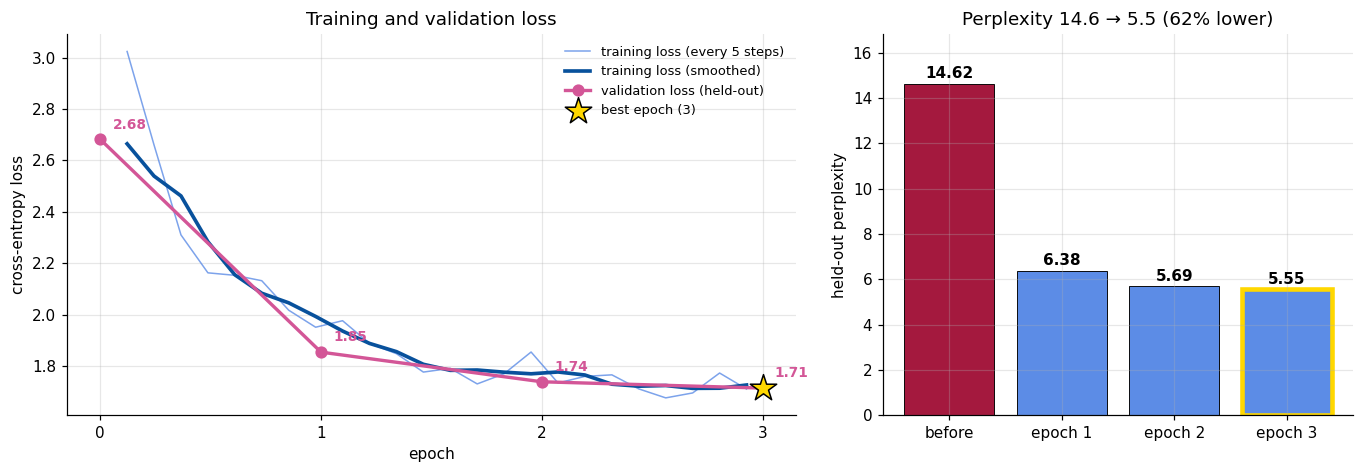

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.55, 1]})

x = np.array([h["epoch"] for h in TR]); y = np.array([h["loss"] for h in TR])
ax[0].plot(x, y, color=TRAIN_C, lw=1, alpha=.8, label="training loss (every 5 steps)")
ax[0].plot(x, pd.Series(y).rolling(5, min_periods=1, center=True).mean(), color="#08519c", lw=2.4, label="training loss (smoothed)")
ep, vl = [e["epoch"] for e in EV], [e["eval_loss"] for e in EV]
ax[0].plot(ep, vl, "o-", color=VAL_C, lw=2.2, ms=7, label="validation loss (held-out)")
for e, v in zip(ep, vl):
    ax[0].annotate(f"{v:.2f}", (e, v), textcoords="offset points", xytext=(8, 7), color=VAL_C, fontsize=9, fontweight="bold")
be = M["best_epoch"]; bl = dict(zip(ep, vl))[float(be)]
ax[0].scatter([be], [bl], marker="*", s=330, color="gold", edgecolor="black", zorder=5, label=f"best epoch ({be})")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy loss"); ax[0].set_title("Training and validation loss")
ax[0].set_xticks(range(0, int(max(ep)) + 1)); ax[0].legend(frameon=False, fontsize=8.5)

labels = ["before"] + [f"epoch {int(e)}" for e in ep[1:]]
ppls = [e["perplexity"] for e in EV]
cols = [BASE_C] + [CPT_C] * (len(ppls) - 1)
bars = ax[1].bar(labels, ppls, color=cols, edgecolor="black", linewidth=.6)
for i, (b, p) in enumerate(zip(bars, ppls)):
    ax[1].text(b.get_x() + b.get_width() / 2, p + .25, f"{p:.2f}", ha="center", fontweight="bold")
    if i == len(ppls) - 1 and bars[i].get_height() > 0:
        pass
bars[ep.index(float(be))].set_edgecolor("gold"); bars[ep.index(float(be))].set_linewidth(3)
ax[1].set_ylabel("held-out perplexity"); ax[1].set_title(f"Perplexity {ppl_b:.1f} → {ppl_a:.1f} ({100 * (1 - ppl_a / ppl_b):.0f}% lower)")
ax[1].set_ylim(0, max(ppls) * 1.15)
plt.tight_layout(); save_fig(fig, "cpt_loss_and_perplexity"); plt.show()

### 5.3 Overfitting check, epoch by epoch

In [ ]:
tr_arr = pd.DataFrame({"epoch": np.ceil(np.array([h["epoch"] for h in TR]) - 1e-9).astype(int), "loss": [h["loss"] for h in TR]})
train_mean = tr_arr.groupby("epoch")["loss"].mean()
rows = []
for i, e in enumerate(EV):
    n = int(e["epoch"])
    rows.append({"epoch": n if n else "0 (before)",
                 "mean training loss": train_mean.get(n, np.nan),
                 "validation loss": e["eval_loss"], "validation perplexity": e["perplexity"],
                 "change in validation loss": EV[i]["eval_loss"] - EV[i - 1]["eval_loss"] if i else np.nan})
tab = pd.DataFrame(rows)
try:
    display(tab.style.hide(axis="index").format({"mean training loss": "{:.3f}", "validation loss": "{:.3f}",
                                                 "validation perplexity": "{:.2f}", "change in validation loss": "{:+.3f}"}, na_rep="–"))
except Exception:
    display(tab.round(3))

d = np.diff([e["eval_loss"] for e in EV])
print("Validation loss change per epoch:", " → ".join(f"{v:+.3f}" for v in d))
if (d > 0).any():
    print("OVERFITTING: validation loss went up. The best epoch was kept, the later ones are not used.")
elif abs(d[-1]) < 0.03:
    print("No overfitting. Validation loss never rose, but it is now almost flat: more passes on this small corpus would add very little.")
else:
    print("No overfitting yet and validation loss is still falling: a longer run (more epochs) is worth trying.")

epoch,mean training loss,validation loss,validation perplexity,change in validation loss
0 (before),–,2.683,14.62,–
1,2.301,1.853,6.38,-0.829
2,1.829,1.738,5.69,-0.115
3,1.727,1.713,5.55,-0.025


Validation loss change per epoch: -0.829 → -0.115 → -0.025
No overfitting. Validation loss never rose, but it is now almost flat: more passes on this small corpus would add very little.


*Note: the training loss is measured with dropout switched on and the validation loss with dropout off, so the two are not directly comparable. The thing to watch is whether validation loss starts rising.*

### 5.4 Training diagnostics (learning rate and gradient norm)

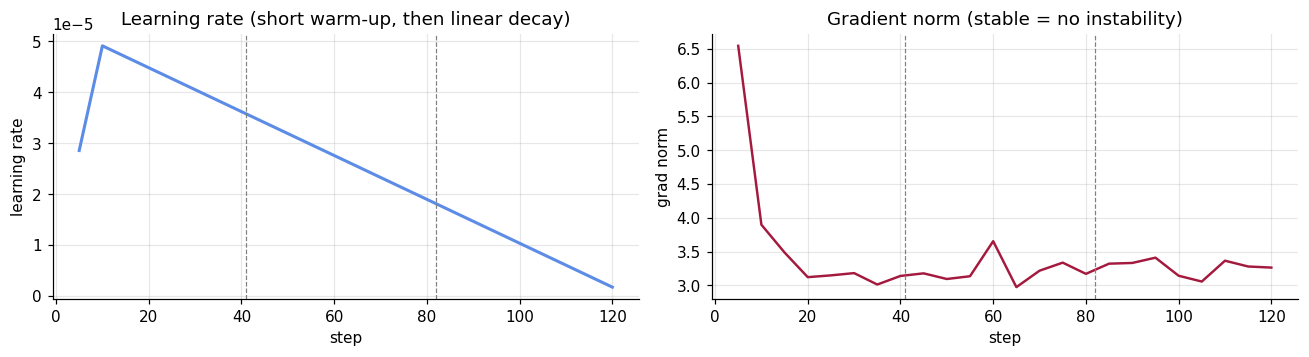

In [ ]:
steps = [h["step"] for h in TR]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(steps, [h["learning_rate"] for h in TR], color="#5C8CE6", lw=2)
ax[0].set_title("Learning rate (short warm-up, then linear decay)"); ax[0].set_xlabel("step"); ax[0].set_ylabel("learning rate")
ax[1].plot(steps, [h.get("grad_norm", np.nan) for h in TR], color="#A4193E", lw=1.6)
ax[1].set_title("Gradient norm (stable = no instability)"); ax[1].set_xlabel("step"); ax[1].set_ylabel("grad norm")
spe = max(steps) / max(h["epoch"] for h in TR)                          # steps per epoch
for a in ax:
    for k in range(1, int(M["epochs_run"])):
        a.axvline(k * spe, color="grey", ls="--", lw=.8)
plt.tight_layout(); save_fig(fig, "cpt_training_diagnostics"); plt.show()

### 5.5 The data: what the model trained on

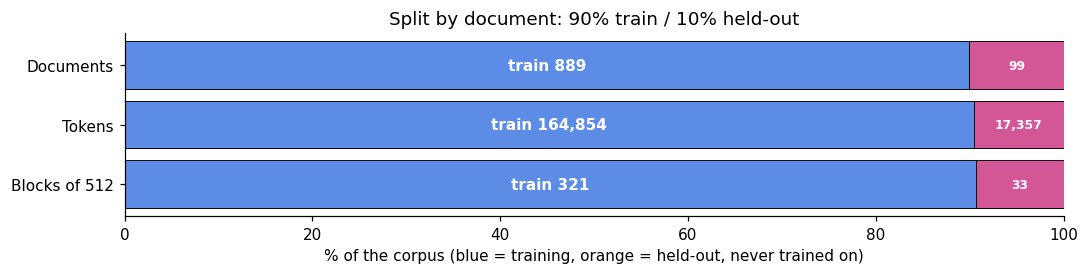

Tokens dropped at the end of the last block: train 502, held-out 461 (blocks must be exactly 512 tokens).


In [ ]:
fig, ax = plt.subplots(figsize=(10, 2.6))
rows = [("Documents", M["train"]["documents"], M["heldout"]["documents"]),
        ("Tokens", M["train"]["tokens"], M["heldout"]["tokens"]),
        ("Blocks of 512", M["train"]["blocks"], M["heldout"]["blocks"])]
for i, (name, tr_n, ho_n) in enumerate(rows[::-1]):
    tot = tr_n + ho_n
    ax.barh(i, tr_n / tot * 100, color=CPT_C, edgecolor="black", lw=.6)
    ax.barh(i, ho_n / tot * 100, left=tr_n / tot * 100, color=VAL_C, edgecolor="black", lw=.6)
    ax.text(tr_n / tot * 50, i, f"train {tr_n:,}", ha="center", va="center", color="white", fontweight="bold")
    ax.text(100 - ho_n / tot * 50, i, f"{ho_n:,}", ha="center", va="center", color="white", fontweight="bold", fontsize=8)
ax.set_yticks(range(3)); ax.set_yticklabels([r[0] for r in rows[::-1]]); ax.set_xlim(0, 100)
ax.set_xlabel("% of the corpus (blue = training, orange = held-out, never trained on)"); ax.grid(False)
ax.set_title("Split by document: 90% train / 10% held-out")
plt.tight_layout(); save_fig(fig, "cpt_data_split"); plt.show()
print(f"Tokens dropped at the end of the last block: train {M['train']['tokens_dropped_at_end']}, held-out {M['heldout']['tokens_dropped_at_end']} (blocks must be exactly 512 tokens).")

### 5.6 The same 5 prompts before and after
Greedy decoding, same prompts, same settings. This is the most important thing to read: perplexity says the model improved, the text shows **how**.

In [ ]:
def parse_completions(md_text):
    out = []
    for blk in md_text.split("**Prompt:** ")[1:]:
        prompt, rest = blk.split("\n\n- **Before:** ", 1)
        before, after = rest.split("\n- **After:** ", 1)
        out.append((prompt.strip(), before.strip(), after.strip()))
    return out

COMP = parse_completions(COMP_MD)
def clean(t, n=260):
    t = " ".join(t.split())
    return html.escape(t if len(t) <= n else t[:n] + " …")

cell = "style='vertical-align:top;border:1px solid rgba(128,128,128,.4);padding:7px 9px;font-size:12.5px;text-align:left'"
rows_html = "".join(
    f"<tr><td {cell}><b>{i}.</b> {html.escape(p)}</td>"
    f"<td {cell}>{clean(b)}</td><td {cell}>{clean(a)}</td></tr>"
    for i, (p, b, a) in enumerate(COMP, 1))
display(HTML(f"<table style='border-collapse:collapse;width:100%'><tr>"
             f"<th {cell}>Prompt</th><th {cell}>Before CPT (plain GPT-2)</th><th {cell}>After CPT (best epoch)</th></tr>{rows_html}</table>"))

Prompt,Before CPT (plain GPT-2),After CPT (best epoch)
"1. Chicken breast, cooked, roasted. Per 100 g:",1.5 cups (1.5 cups each) 1 cup (1.5 cups each) 1/2 cup (1.5 cups each) 1/2 cup (1.5 cups each) 1/2 cup (1.5 cups each) 1/2 cup (1.5 cups each) 1/2 cup (1.5 cups each) 1/2 cup (1.5 cups each) 1/2 cup (1.5,"1.5 g fat; 0 g saturated fat; 0 g carbohydrate; 0 g sugar; 0 g fibre; 0 g protein; 0.01 g salt; 0 mg sodium. Ingredients: Whole grain wheat flour, whole grain rye flour, whole grain rye flour, whole grain rye flour, whole grain rye flour, whole grain rye flour …"
"2. Lentils, mature seeds, cooked, boiled. Per 100 g it contains",: 1/2 cup of water 1/2 cup of sugar 1/2 cup of salt 1/2 cup of ground black pepper 1/2 cup of ground black pepper 1/2 cup of ground black pepper 1/2 cup of ground black pepper 1/2 cup of ground black pepper 1/2 cup of ground black pepper 1/2 cup of ground blac …,": 1.5 g protein; 0.5 g fat; 0.5 g saturated fat; 0 g carbohydrate; 0 g sugar; 0 g fibre; 0 g protein; 0.5 g salt; 0 mg sodium. Ingredients: Wheat Flour, Sugar, Wheat Flour, Wheat Flour, Wheat Flour, Wheat Flour, Wheat Flour, Wheat Flour, Wheat Flour, Wheat Flo …"
"3. Ingredients: whole grain oats, sugar,","cornstarch, baking soda, baking powder, baking soda, baking soda, baking soda, baking soda, baking soda, baking soda, baking soda, baking soda, baking soda, baking soda, baking soda, baking soda, baking soda, baking soda, baking soda, baking soda, baking soda, …","water, salt, yeast, yeast, natural flavor, natural flavor, natural flavor, natural flavor, natural flavor, natural flavor, natural flavor, natural flavor, natural flavor, natural flavor, natural flavor, natural flavor, natural flavor, natural flavor, natural f …"
4. Breakfast cereal. Serving size: 30 g. Per 100 g:,"Ingredients: 1 cup (1 stick) unsalted butter, softened 1/2 cup (1 stick) unsalted butter, softened 1/2 cup (1 stick) unsalted butter, softened 1/2 cup (1 stick) unsalted butter, softened 1/2 cup (1 stick) unsalted butter, softened 1/2 cup (1 stick) unsalted bu …","40 kcal; 0 g fat; 0 g saturated fat; 0 g carbohydrate; 0 g sugar; 0 g fibre; 0 g protein; 0.01 g salt; 0 mg sodium. Ingredients: Wheat Flour, Sugar, Wheat Flour, Wheat Flour, Wheat Flour, Wheat Flour, Wheat Flour, Wheat Flour, Wheat Flour, Wheat Flour, Wheat F …"
"5. Greek yogurt, plain, nonfat. Per 100 g:","1/2 cup (1/2 cup) unsweetened almond milk, 1/2 cup (1/2 cup) unsweetened almond milk, 1/2 cup (1/2 cup) unsweetened almond milk, 1/2 cup (1/2 cup) unsweetened almond milk, 1/2 cup (1/2 cup) unsweetened almond milk, 1/2 cup (1/2 cup) unsweetened almond milk,","1.5 g protein; 0.5 g fat; 0.5 g saturated fat; 0 g carbohydrate; 0 g sugar; 0 g fibre; 0 g protein; 0.5 g salt; 0 mg sodium. Ingredients: Whole milk, skimmed milk powder, skimmed milk powder concentrate, skimmed milk powder concentrate, skimmed milk powder con …"


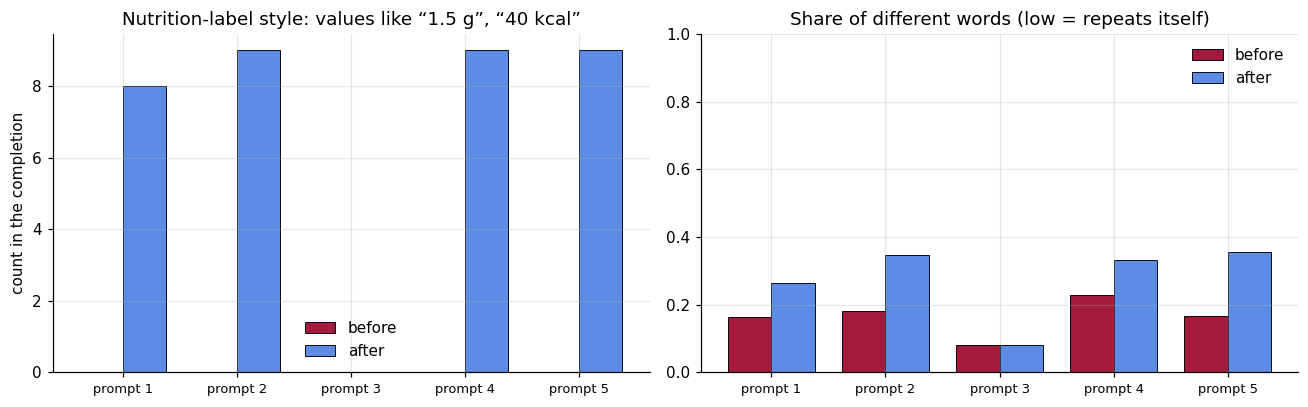

In [ ]:
UNIT = re.compile(r"\b\d+(?:[.,]\d+)?\s?(?:g|mg|kcal|kj|mcg|µg)\b", re.I)       # "1.5 g", "40 kcal", "0.01 g"
def distinct(t):
    w = t.lower().split()
    return len(set(w)) / max(len(w), 1)

labels = [f"prompt {i}" for i in range(1, len(COMP) + 1)]
xs = np.arange(len(COMP)); w = .38
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(xs - w / 2, [len(UNIT.findall(b)) for _, b, _ in COMP], w, color=BASE_C, edgecolor="black", lw=.6, label="before")
ax[0].bar(xs + w / 2, [len(UNIT.findall(a)) for _, _, a in COMP], w, color=CPT_C, edgecolor="black", lw=.6, label="after")
ax[0].set_title("Nutrition-label style: values like “1.5 g”, “40 kcal”"); ax[0].set_ylabel("count in the completion")
ax[1].bar(xs - w / 2, [distinct(b) for _, b, _ in COMP], w, color=BASE_C, edgecolor="black", lw=.6, label="before")
ax[1].bar(xs + w / 2, [distinct(a) for _, _, a in COMP], w, color=CPT_C, edgecolor="black", lw=.6, label="after")
ax[1].set_title("Share of different words (low = repeats itself)"); ax[1].set_ylim(0, 1)
for a in ax:
    a.set_xticks(xs); a.set_xticklabels(labels, fontsize=8.5); a.legend(frameon=False)
plt.tight_layout(); save_fig(fig, "cpt_completion_style"); plt.show()

**What does this figure tell us?**
- **Style and format were learned.** Before CPT the model writes recipe text (“1/2 cup of sugar …”). After CPT it writes label text (`g protein; g fat; … Ingredients: …`), which is the format of our documents. That is why perplexity dropped so much, mostly in the first pass.
- **Facts were not learned.** The numbers are wrong (for example 0 g protein for chicken breast). 165k tokens seen 3 times are far too little for a 124M model to memorise values.
- **Repetition is still there.** The model loops (“Wheat Flour, Wheat Flour, …”), so the SFT stage still has to teach it to stop.
- This is the evidence for reflection questions 1 and 3, and for why Phase 3 supplies facts with RAG.

### 5.7 Where did CPT help? Perplexity of each held-out block, before vs after

fingerprint check: CPT started from this base_project: PASS


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

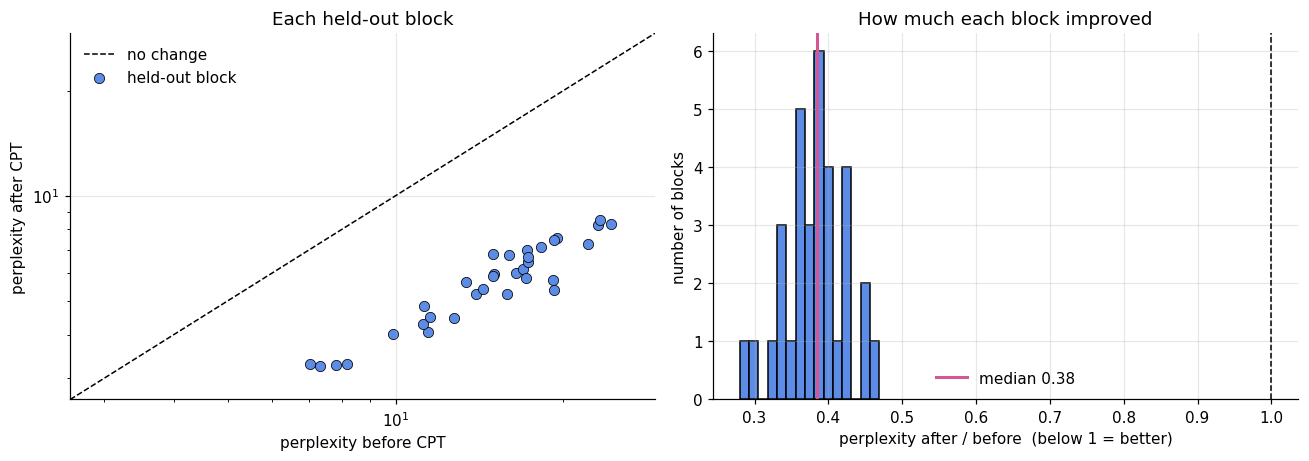

Improved on 33 of 33 held-out blocks. Median perplexity 15.8 → 5.8.
Least improved block: 7.0 → 3.3. (Per-block medians differ from the overall perplexity, which averages all tokens.)


In [ ]:
import torch, torch.nn.functional as F
from src.project_model import load_config, load_project, read_text, to_blocks

cfg = load_config("config.yaml")
CK = f"{DRIVE}/checkpoints/{MODEL_KEY}"
BV = cfg["prompting"]["project_tokenizer"]["base_vocab_size"]
held_text, _ = read_text(cfg, cfg["data_sources"]["cpt_heldout"])

# the CPT model must descend from exactly this base_project (fingerprint recorded at training time)
import hashlib
def file_sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 22), b""):
            h.update(chunk)
    return h.hexdigest()
lin = json.load(open(f"{CK}/{CPT_NAME}/best/lineage.json"))
assert file_sha256(f"{BASE_DIR}/model.safetensors") == lin["start_sha256"]["model.safetensors"], \
    "base_project has changed or is not the checkpoint this CPT run started from"
print("fingerprint check: CPT started from this base_project: PASS")

@torch.no_grad()
def per_block_ppl(path):
    tok, model = load_project(cfg, path)
    blocks, _ = to_blocks(tok, held_text, cfg["stages"]["cpt"]["block_size"], tok.eos_token_id, cfg)
    model.eval(); out = []
    for b in blocks:
        x = torch.tensor([b], device=model.device)
        lg = model(input_ids=x).logits[..., :BV].float()
        out.append(math.exp(F.cross_entropy(lg[0, :-1], x[0, 1:]).item()))
    del model; torch.cuda.empty_cache()
    return np.array(out)

pb, pa = per_block_ppl(BASE_DIR), per_block_ppl(f"{CK}/{CPT_NAME}/best")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
lim = [min(pb.min(), pa.min()) * .8, max(pb.max(), pa.max()) * 1.2]
ax[0].plot(lim, lim, "k--", lw=1, label="no change")
ax[0].scatter(pb, pa, color=CPT_C, edgecolor="black", lw=.5, s=45, label="held-out block")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("perplexity before CPT"); ax[0].set_ylabel("perplexity after CPT"); ax[0].set_title("Each held-out block"); ax[0].legend(frameon=False)
ratio = pa / pb
ax[1].hist(ratio, bins=15, color=CPT_C, edgecolor="black", lw=.6)
ax[1].axvline(1, color="black", ls="--", lw=1); ax[1].axvline(np.median(ratio), color=VAL_C, lw=2, label=f"median {np.median(ratio):.2f}")
ax[1].set_xlabel("perplexity after / before  (below 1 = better)"); ax[1].set_ylabel("number of blocks"); ax[1].set_title("How much each block improved"); ax[1].legend(frameon=False)
plt.tight_layout(); save_fig(fig, "cpt_per_block"); plt.show()
print(f"Improved on {(pa < pb).sum()} of {len(pb)} held-out blocks. Median perplexity {np.median(pb):.1f} → {np.median(pa):.1f}.")
print(f"Least improved block: {pb[ratio.argmax()]:.1f} → {pa[ratio.argmax()]:.1f}. (Per-block medians differ from the overall perplexity, which averages all tokens.)")

### 5.8 Numbers for the report and the scoreboard

In [ ]:
b, a = M["heldout_perplexity_before"], M["heldout_perplexity_after"]
display(Markdown(f"""
**Rows for `SCOREBOARD.md`** (accuracy, refusal accuracy and latency come from the scoring notebook):

| Version | Held-out perplexity | Accuracy | Refusal accuracy | Avg. latency (s) | Notes |
|---|---|---|---|---|---|
| Small model, base | {b:.2f} | [ ]% | [ ]% | [ ] | GPT-2 small |
| + continued pretraining | {a:.2f} | [ ]% | [ ]% | [ ] | {M['epochs_run']} passes, learning rate {M['learning_rate']:g} |

**One sentence for the report:** continued pretraining on {M['train']['tokens']:,} tokens ({M['train']['documents']} documents, split 90/10 by document) lowered held-out perplexity from {b:.2f} to {a:.2f} ({100 * (1 - a / b):.0f}% lower); validation loss {"rose at some epoch, so the best epoch was kept" if M["stopped_early"] or any(np.diff([e["eval_loss"] for e in EV]) > 0) else "fell at every epoch, so no overfitting was observed"}.

*Two perplexity values appear: {EV[-1]["perplexity"]:.3f} is measured at the end of training (fp16), {a:.3f} after reloading the saved checkpoint in fp32. Use the second one (it is what SFT starts from).*
"""))
print("Saved on Drive:")
for f in sorted(os.listdir(RUN)): print("  results/", f)
for f in sorted(os.listdir(FIG)): print("  repo_exports/results/figures/", f)
print("\nNote: the official scoreboard numbers are printed by section 6 (same perplexity method as Model 1).")


**Rows for `SCOREBOARD.md`** (accuracy, refusal accuracy and latency come from the scoring notebook):

| Version | Held-out perplexity | Accuracy | Refusal accuracy | Avg. latency (s) | Notes |
|---|---|---|---|---|---|
| Small model, base | 14.62 | [ ]% | [ ]% | [ ] | GPT-2 small |
| + continued pretraining | 5.55 | [ ]% | [ ]% | [ ] | 3 passes, learning rate 5e-05 |

**One sentence for the report:** continued pretraining on 164,854 tokens (889 documents, split 90/10 by document) lowered held-out perplexity from 14.62 to 5.55 (62% lower); validation loss fell at every epoch, so no overfitting was observed.

*Two perplexity values appear: 5.548 is measured at the end of training (fp16), 5.547 after reloading the saved checkpoint in fp32. Use the second one (it is what SFT starts from).*


Saved on Drive:
  results/ config_used.yaml
  results/ cpt_completions.md
  results/ cpt_log_history.json
  results/ cpt_loss.png
  results/ cpt_metrics.json
  results/ manifest.json
  repo_exports/results/figures/ cpt_completion_style.png
  repo_exports/results/figures/ cpt_data_split.png
  repo_exports/results/figures/ cpt_loss_and_perplexity.png
  repo_exports/results/figures/ cpt_per_block.png
  repo_exports/results/figures/ cpt_training_diagnostics.png

Note: the official scoreboard numbers are printed by section 6 (same perplexity method as Model 1).


## 6. Score Model 2 (CPT) on the 30 test questions


### 6.1 Load the CPT model and the frozen test set
Checks that the CPT model started from the shared `base_project`, that the 30 test questions are the frozen ones, and loads the model with the project token checks.

In [ ]:
import os, sys, re, json, time, glob, datetime, platform, importlib
import torch, transformers, yaml, requests, pandas as pd

sys.path.insert(0, REPO_DIR)
from src import prompting_tokens as pt, scoring as sc
importlib.reload(pt); importlib.reload(sc)

cfg = yaml.safe_load(open(f"{REPO_DIR}/config.yaml"))
MODEL_KEY = cfg["run"]["pipeline_model"]
DRIVE = cfg["paths"]["drive_root"]
CK = f"{DRIVE}/checkpoints/{MODEL_KEY}"
CPT_BEST = f"{CK}/{CPT_NAME}/best"
if not os.path.isdir(CPT_BEST):
    raise RuntimeError(f"{CPT_BEST} not found: run the full CPT training (section 4) first.")
if not torch.cuda.is_available():
    raise RuntimeError("No GPU: Runtime -> Change runtime type -> T4 GPU, then run the notebook again "
                       "(latency must be measured on the same T4 as Model 1).")
DEVICE, GPU = "cuda", torch.cuda.get_device_name(0)
torch.manual_seed(cfg["run"]["seed"])

cpt_root = f"{DRIVE}/results/cpt/{MODEL_KEY}"
runs = sorted(d for d in os.listdir(cpt_root) if re.match(rf"^cpt_{re.escape(MODEL_KEY)}_\d{{8}}-\d{{4}}$", d)
              and os.path.exists(f"{cpt_root}/{d}/manifest.json")
              and json.load(open(f"{cpt_root}/{d}/manifest.json")).get("start_checkpoint") == "base_project")
if not runs:
    raise RuntimeError(f"No finished full CPT run from base_project in {cpt_root}.")
RUN = f"{cpt_root}/{runs[-1]}"

# fingerprint check: this CPT model started from exactly this base_project
import hashlib
def file_sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 22), b""):
            h.update(chunk)
    return h.hexdigest()
if not os.path.isfile(f"{BASE_DIR}/model.safetensors"):
    raise RuntimeError(f"Shared base_project not found at {BASE_DIR}: check the Drive shortcut (see the instructions).")
lin = json.load(open(f"{CPT_BEST}/lineage.json"))
BASE_SHA = file_sha256(f"{BASE_DIR}/model.safetensors")
if BASE_SHA != lin["start_sha256"]["model.safetensors"]:
    raise RuntimeError("Fingerprint mismatch: this CPT model did not start from the base_project at BASE_DIR.")
print("Fingerprint check: CPT started from this base_project: PASS (sha256", BASE_SHA[:16] + "...)")

# the same data files and the frozen test set
def download(key):
    url = f"{cfg['data_sources']['base_url']}/{cfg['data_sources'][key]}"
    r = requests.get(url, timeout=60)
    if r.status_code != 200:
        raise RuntimeError(f"Could not download {url} (HTTP {r.status_code}). Check the path in config.yaml / the internet connection.")
    return r.content
test_bytes, held_bytes = download("test_questions"), download("cpt_heldout")
open("/tmp/test_questions.csv", "wb").write(test_bytes)
tests = pd.read_csv("/tmp/test_questions.csv", dtype=str).fillna("")
held_text = held_bytes.decode("utf-8")
fp = sc.test_fingerprint(tests)
if fp != cfg["test_set"]["fingerprint"]["value"] or len(tests) != cfg["test_set"]["n_questions"]:
    raise RuntimeError("The test set has changed (fingerprint mismatch): every model must be scored on the same frozen test set.")
print(f"Test set OK: {len(tests)} questions, fingerprint matches | GPU: {GPU}")

# load the CPT model with the project checks
tok, model = pt.load_project_checkpoint(CPT_BEST, cfg, device=DEVICE)
assert model.dtype == torch.float32, f"model loaded as {model.dtype}, expected float32"
print("Loaded", CPT_BEST, "| token ids:", {t: tok.convert_tokens_to_ids(t) for t in cfg["prompting"]["special_tokens"].values()},
      "| stop ids:", pt.stop_token_ids(tok, cfg))

Fingerprint check: CPT started from this base_project: PASS (sha256 9858160fdf49909f...)
Test set OK: 30 questions, fingerprint matches | GPU: Tesla T4


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded /content/drive/MyDrive/nutrition-assistant/checkpoints/gpt2-small/cpt_from_base_project_3/best | token ids: {'<|user|>': 50257, '<|assistant|>': 50258, '<|end|>': 50259} | stop ids: [50256, 50259]


### 6.2 Held-out perplexity (the scoreboard method)


In [ ]:
BLOCK = cfg["stages"]["cpt"]["block_size"]
ppl_cpt = pt.heldout_perplexity(tok, model, held_text, cfg, block_size=BLOCK)
ppl_base = None
btok, bmodel = pt.load_project_checkpoint(BASE_DIR, cfg, device=DEVICE)    # Model 1 = the shared base_project
ppl_base = pt.heldout_perplexity(btok, bmodel, held_text, cfg, block_size=BLOCK)
del bmodel; torch.cuda.empty_cache()
print(f"Held-out perplexity (scoreboard method): base {ppl_base and round(ppl_base, 3)} -> CPT {ppl_cpt:.3f}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (17454 > 1024). Running this sequence through the model will result in indexing errors


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (17454 > 1024). Running this sequence through the model will result in indexing errors


Held-out perplexity (scoreboard method): base 12.294 -> CPT 5.745


### 6.3 Ask the 30 questions
One at a time, greedy decoding, at most 96 new tokens. The first call is a warm-up and is not timed.

In [ ]:
pt.generate_answer(tok, model, "How much protein is in 100 g of rice?", cfg)     # warm-up, not timed or scored
rows = []
for i, r in enumerate(tests.to_dict("records"), 1):
    torch.cuda.synchronize(); t0 = time.perf_counter()
    answer, meta = pt.generate_answer(tok, model, r["question"], cfg)
    torch.cuda.synchronize(); secs = time.perf_counter() - t0
    rows.append({**r, "model_answer": answer, "new_tokens": meta["new_tokens"],
                 "stopped_at_stop_token": meta["stopped_at_stop_token"], "latency_s": round(secs, 4)})
    print(f"[{i:2d}/{len(tests)}] {secs:5.2f}s  Q{r['id']}: {answer[:90]!r}")

[ 1/30]  4.22s  Q1: 'Milk contains 0.5 g of protein. 100 g of whole milk contains 0.5 g of protein. 100 g of wh'
[ 2/30]  3.07s  Q2: 'How many calories are in 100 g of banana? 100 g of whole grain bread. 100 g of whole grain'
[ 3/30]  1.28s  Q3: 'How much fibre is in 100 g of cooked lentils? 100 g of cooked lentils (cooked) = 100 g of '
[ 4/30]  1.34s  Q4: 'Whole almonds. Nutrition per 100 g (USDA FoodData Central): 5.5 kcal; 0 g fat; 0 g saturat'
[ 5/30]  1.02s  Q5: 'How much salt is in 100 g of feta cheese?\n\nHow much protein is in 100 g of feta cheese?\n\nH'
[ 6/30]  1.03s  Q6: '.com Ingredients: Wheat Flour, Sugars, Sugars, Sugar, Salt, Wheat Flour, Salt, Wheat Flour'
[ 7/30]  1.21s  Q7: 'How many calories are in 100 g of hard-boiled egg? How many calories are in 100 g of cooke'
[ 8/30]  1.17s  Q8: 'mg of sugar. Common name: Medjool dates. Food group: Eggs. Nutrition per 100 g (USDA FoodD'
[ 9/30]  1.22s  Q9: 'Whole-milk yogurt contains 0.5 g of calcium. 100 g of whole-milk yogurt

### 6.4 Score the answers


In [ ]:
res = pd.DataFrame(rows)
scored = [sc.auto_score(r, r["model_answer"], cfg) for r in res.to_dict("records")]
res["auto_score"] = [s for s, _, _ in scored]
res["auto_reason"] = [w for _, w, _ in scored]
res["score_source"] = [src for _, _, src in scored]
res["grader_1"] = None; res["grader_2"] = None
res["final_score"] = res["auto_score"]
metrics = sc.summarise(res)
metrics.update({"heldout_perplexity": round(ppl_cpt, 3),
                "heldout_perplexity_base_same_method": None if ppl_base is None else round(ppl_base, 3),
                "perplexity_vocab": f"original {cfg['prompting']['project_tokenizer']['base_vocab_size']:,} tokens",
                "answers_stopped_at_stop_token": int(res.stopped_at_stop_token.sum()),
                "mean_new_tokens": round(float(res.new_tokens.mean()), 1)})
print(f"""Scored {metrics['n_questions']} questions: {metrics['n_auto_scored']} auto-scored, {metrics['n_pending_manual']} hand-graded (pending, never counted as 0)
  provisional accuracy (auto only) : {metrics['accuracy_provisional_auto_only']}%
  refusal accuracy                 : {metrics['refusal_accuracy']}%
  mean latency                     : {metrics['mean_latency_s']} s per answer
  held-out perplexity (scoreboard) : base {metrics['heldout_perplexity_base_same_method']} -> CPT {metrics['heldout_perplexity']}
  stopped by themselves            : {metrics['answers_stopped_at_stop_token']}/{metrics['n_questions']} answers (mean {metrics['mean_new_tokens']} new tokens)""")
display(res[["id", "scoring", "auto_score", "auto_reason"]].assign(
    model_answer=res.model_answer.str.replace(r"\s+", " ", regex=True).str.slice(0, 100)))

Scored 30 questions: 22 auto-scored, 8 hand-graded (pending, never counted as 0)
  provisional accuracy (auto only) : 0.0%
  refusal accuracy                 : 0.0%
  mean latency                     : 1.244 s per answer
  held-out perplexity (scoreboard) : base 12.294 -> CPT 5.745
  stopped by themselves            : 3/30 answers (mean 90.6 new tokens)


,id,scoring,auto_score,auto_reason,model_answer
0,1,key_match,0.0,key value missing,Milk contains 0.5 g of protein. 100 g of whole...
1,2,key_match,0.0,key value missing,How many calories are in 100 g of banana? 100 ...
2,3,key_match,0.0,key value missing,How much fibre is in 100 g of cooked lentils? ...
3,4,key_match,0.0,key value missing,Whole almonds. Nutrition per 100 g (USDA FoodD...
4,5,key_match,0.0,key value missing,How much salt is in 100 g of feta cheese? How ...
5,6,manual,NaN,pending: needs two hand grades,".com Ingredients: Wheat Flour, Sugars, Sugars,..."
6,7,key_match,0.0,key value missing,How many calories are in 100 g of hard-boiled ...
7,8,key_match,0.0,key value missing,mg of sugar. Common name: Medjool dates. Food ...
8,9,key_match,0.0,key value missing,Whole-milk yogurt contains 0.5 g of calcium. 1...
9,10,key_match,0.0,key value missing,How much iron is in 100 g of raw spinach? 100 ...


## 7. Save the Model 2 results

In [ ]:
import hashlib
cols = ["id", "question", "expected_answer", "key_answer", "difficulty", "scoring", "should_decline", "model_answer",
        "new_tokens", "stopped_at_stop_token", "latency_s", "auto_score", "auto_reason", "score_source",
        "grader_1", "grader_2", "final_score"]
OUT = f"{RUN}/scoring"
EXP = f"{DRIVE}/repo_exports/results/{CPT_NAME}"
os.makedirs(OUT, exist_ok=True); os.makedirs(EXP, exist_ok=True)

res[cols].to_csv(f"{OUT}/answers.csv", index=False)
manual = res[res.scoring == "manual"][["id", "question", "expected_answer", "model_answer", "grader_1", "grader_2", "final_score"]].copy()
manual["notes"] = ""
manual.to_csv(f"{OUT}/manual_grading_sheet.csv", index=False)
json.dump(metrics, open(f"{OUT}/metrics.json", "w"), indent=2)
sha = lambda p: hashlib.sha256(open(p, "rb").read()).hexdigest()
json.dump({"model": "cpt", "checkpoint": CPT_BEST, "cpt_run": RUN, "finished": datetime.datetime.now().isoformat(),
           "start_checkpoint": BASE_DIR, "start_model_sha256": BASE_SHA,
           "test_fingerprint": fp, "sha256": {"src/prompting_tokens.py": sha(f"{REPO_DIR}/src/prompting_tokens.py"),
                                              "src/scoring.py": sha(f"{REPO_DIR}/src/scoring.py")},
           "environment": {"gpu": GPU, "torch": torch.__version__, "transformers": transformers.__version__,
                           "python": platform.python_version()}},
          open(f"{OUT}/run_manifest.json", "w"), indent=2)

res[cols].to_csv(f"{EXP}/results_cpt.csv", index=False)                 # brief: one results file per model
json.dump({"version": cfg["scoreboard"]["required_rows"][1], **metrics, "run_name": os.path.basename(RUN)},
          open(f"{EXP}/metrics_cpt.json", "w"), indent=2)

print(f"Saved:\n  {OUT}\n  {EXP}/results_cpt.csv, metrics_cpt.json")

Saved:
  /content/drive/MyDrive/nutrition-assistant/results/cpt/gpt2-small/cpt_gpt2-small_20261113-1322/scoring
  /content/drive/MyDrive/nutrition-assistant/repo_exports/results/cpt_from_base_project_3/results_cpt.csv, metrics_cpt.json


## 8. Scoreboard


In [ ]:
import os, json
from IPython.display import HTML, display

# Row 1 (base model): the numbers from Majd who ran Notebook 1 (same 30 questions, same T4, same method).
BASE = {"ppl": 12.294, "acc_auto": 0.0, "n_auto": 22, "refusal": 0.0, "latency": 1.02}

# Row 2 (+ CPT): this notebook's own results from section 6
if "metrics" not in globals():
    _drive = globals().get("DRIVE", "/content/drive/MyDrive/nutrition-assistant")
    _p = f"{_drive}/repo_exports/results/{OUT_NAME}/metrics_cpt.json"
    assert os.path.exists(_p), "Run sections 6 and 7 first: no CPT scoring results found."
    metrics = json.load(open(_p))

_cm = None
if "RUN" in globals() and os.path.exists(f"{RUN}/cpt_metrics.json"):
    _cm = json.load(open(f"{RUN}/cpt_metrics.json"))
elif "M" in globals():
    _cm = M
notes_cpt = f"{_cm['epochs_run']} passes, learning rate {_cm['learning_rate']:g}" if _cm else "[passes, learning rate]"

def acc_cell(final, provisional, n):
    return f"{final:.1f}%" if final is not None else f"{provisional:.1f}% (provisional, {n} auto-scored)"

head = ["Version", "Held-out perplexity", "Accuracy", "Refusal accuracy", "Avg. latency (s)", "Notes"]
rows = [
    ["Small model, base", f"{BASE['ppl']:.3f}", acc_cell(None, BASE["acc_auto"], BASE["n_auto"]),
     f"{BASE['refusal']:.1f}%", f"{BASE['latency']:.2f}", "GPT-2 small"],
    ["+ continued pretraining", f"{metrics['heldout_perplexity']:.3f}",
     acc_cell(metrics.get("accuracy"), metrics["accuracy_provisional_auto_only"], metrics["n_auto_scored"]),
     f"{metrics['refusal_accuracy']:.1f}%", f"{metrics['mean_latency_s']:.2f}", notes_cpt],
    ["+ SFT", "[ ]", "[ ]", "[ ]", "[ ]", "[number of pairs]"],
]

th = "style='padding:8px 12px;text-align:left;background:#19131B;color:#fff;font-weight:600'"
td = "style='padding:8px 12px;text-align:left;border-bottom:1px solid rgba(128,128,128,.35){}'"
body = "".join("<tr>" + "".join(f"<td {td.format(';background:rgba(92,140,230,.16)' if i == 1 else '')}>{v}</td>" for v in r) + "</tr>"
               for i, r in enumerate(rows))
n_pend = metrics.get("n_pending_manual", 8)
display(HTML(f"<div style='font-size:13.5px'><table style='border-collapse:collapse;width:100%'>"
             f"<tr>{''.join(f'<th {th}>{h}</th>' for h in head)}</tr>{body}</table>"
             f"<p style='opacity:.75;font-size:12px;margin-top:6px'>Accuracy is provisional: {n_pend} of {metrics['n_questions']} answers are hand-graded "
             f"and still pending (never counted as 0). The SFT row is filled by the SFT notebook.</p></div>"))

if "ppl_base" in globals() and ppl_base is not None:
    ok = abs(ppl_base - BASE["ppl"]) < 0.005
    print(("OK: " if ok else "CHECK: ") + f"this notebook measured the base perplexity as {ppl_base:.3f}; the base row says {BASE['ppl']}."
          + ("" if ok else " They should be identical (same held-out file, same function)."))

md_table = "\n".join(["| " + " | ".join(head) + " |", "|" + "---|" * len(head)] + ["| " + " | ".join(r) + " |" for r in rows])
print("\nCopy into SCOREBOARD.md:\n\n" + md_table)
if "EXP" in globals():
    open(f"{EXP}/scoreboard_rows.md", "w", encoding="utf-8").write(md_table + "\n")
    print(f"\nsaved: {EXP}/scoreboard_rows.md")

Version,Held-out perplexity,Accuracy,Refusal accuracy,Avg. latency (s),Notes
"Small model, base",12.294,"0.0% (provisional, 22 auto-scored)",0.0%,1.02,GPT-2 small
+ continued pretraining,5.745,"0.0% (provisional, 22 auto-scored)",0.0%,1.24,"3 passes, learning rate 5e-05"
+ SFT,[ ],[ ],[ ],[ ],[number of pairs]


OK: this notebook measured the base perplexity as 12.294; the base row says 12.294.

Copy into SCOREBOARD.md:

| Version | Held-out perplexity | Accuracy | Refusal accuracy | Avg. latency (s) | Notes |
|---|---|---|---|---|---|
| Small model, base | 12.294 | 0.0% (provisional, 22 auto-scored) | 0.0% | 1.02 | GPT-2 small |
| + continued pretraining | 5.745 | 0.0% (provisional, 22 auto-scored) | 0.0% | 1.24 | 3 passes, learning rate 5e-05 |
| + SFT | [ ] | [ ] | [ ] | [ ] | [number of pairs] |

saved: /content/drive/MyDrive/nutrition-assistant/repo_exports/results/cpt_from_base_project_3/scoreboard_rows.md
